In [ ]:

# SKILL 5 - STEP 1: Dataset Audit Setup

import os
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from collections import Counter

# Define the dataset repository path
repo_path = "/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main"

audit_path = repo_path

print("Dataset Audit Started")
print("Dataset path:", audit_path)
print("Path exists:", os.path.exists(audit_path))


Dataset Audit Started
Dataset path: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main
Path exists: True


In [ ]:

# SKILL 5 - STEP 2: Count Dataset Images

import os

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_files = []

for root, dirs, files in os.walk(audit_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total images found:", len(image_files))

print("\nFirst 10 image files:")
for path in image_files[:10]:
    print(path)


Total images found: 10

First 10 image files:
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/tmc.png
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/labels.jpeg
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/ITD_example2.jpg
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/confusion_matrix_normalized.png
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/ttc.png
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/PR_curve.png
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z

In [ ]:

# SKILL 5 - STEP 3: Image Dimension Analysis

import os
from PIL import Image
import pandas as pd

image_data = []

for path in image_files:
    try:
        with Image.open(path) as img:
            width, height = img.size

            image_data.append({
                "Image": os.path.basename(path),
                "Width": width,
                "Height": height,
                "Format": img.format
            })

    except Exception as e:
        print("Error reading:", path, "|", e)

image_df = pd.DataFrame(image_data)

print("Successfully inspected images:", len(image_df))
print("\nImage dimension details:")
display(image_df.head(10))

if not image_df.empty:
    print("\nUnique image dimensions:")
    print(image_df.groupby(["Width", "Height"]).size())


Successfully inspected images: 10

Image dimension details:


,Image,Width,Height,Format
0,tmc.png,1920,1080,PNG
1,labels.jpeg,845,857,JPEG
2,ITD_example2.jpg,1920,1080,JPEG
3,confusion_matrix_normalized.png,3000,2250,PNG
4,ttc.png,1920,1080,PNG
5,PR_curve.png,2250,1500,PNG
6,ITD_example1.jpg,1920,1080,PNG
7,F1_curve.png,2250,1500,PNG
8,ITD_example3.jpg,1440,1080,PNG
9,lane_behaviour.png,1920,1080,PNG



Unique image dimensions:
Width  Height
845    857       1
1440   1080      1
1920   1080      5
2250   1500      2
3000   2250      1
dtype: int64


In [ ]:

# SKILL 5 - STEP 4: Missing and Unreadable Image Checks

import os
from PIL import Image

missing_files = []
unreadable_files = []

for path in image_files:
    if not os.path.exists(path):
        missing_files.append(path)
        continue

    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        unreadable_files.append(path)

print("Total image paths:", len(image_files))
print("Missing files:", len(missing_files))
print("Unreadable or corrupted images:", len(unreadable_files))

print("\nMissing file list:")
for path in missing_files[:10]:
    print(path)

print("\nUnreadable image list:")
for path in unreadable_files[:10]:
    print(path)


Total image paths: 10
Missing files: 0
Unreadable or corrupted images: 0

Missing file list:

Unreadable image list:


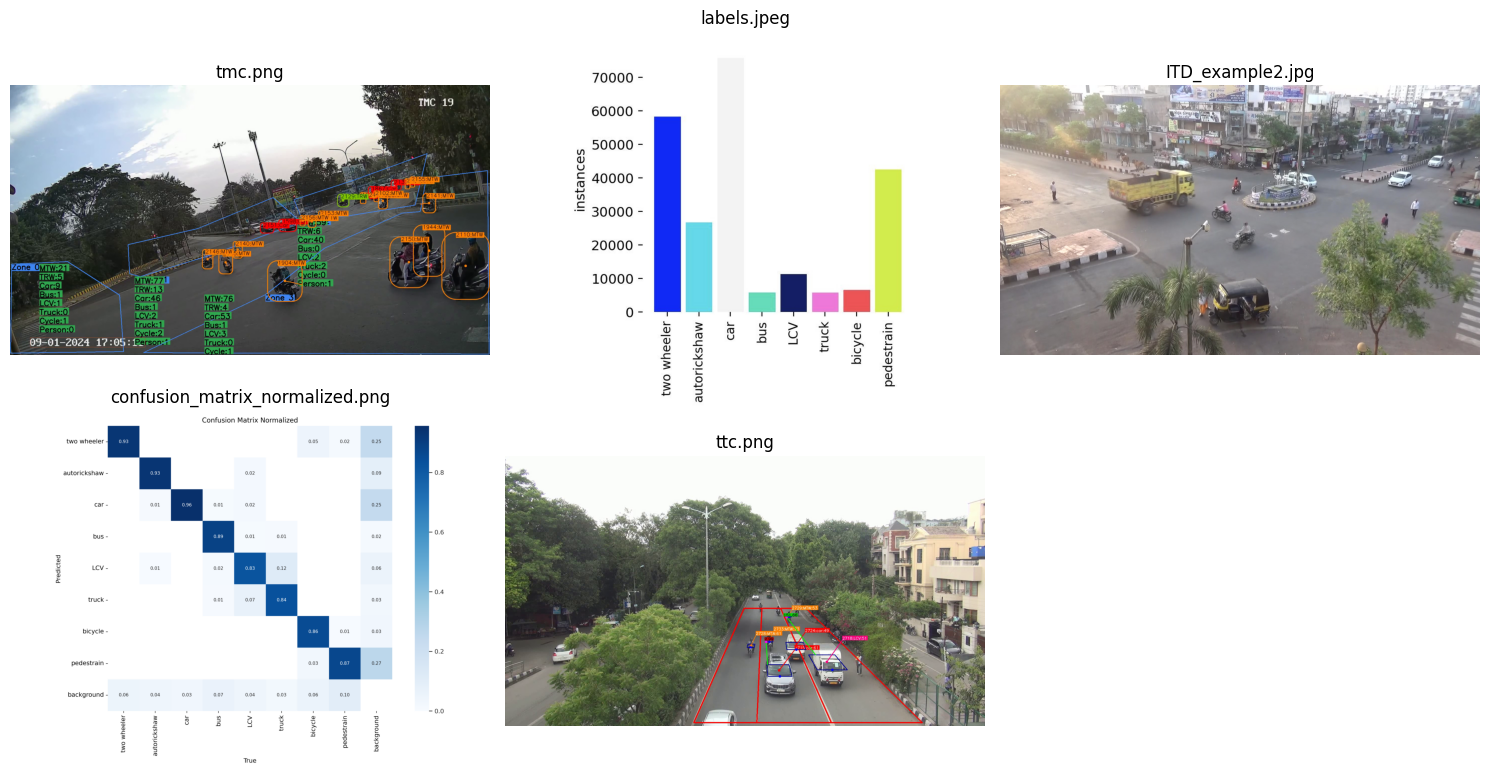

In [ ]:

# SKILL 5 - STEP 5: Visualise Sample Traffic Images

import matplotlib.pyplot as plt
from PIL import Image

if len(image_files) == 0:
    print("No images found. Check the dataset folder.")
else:
    sample_images = image_files[:5]

    plt.figure(figsize=(15, 8))

    for i, path in enumerate(sample_images):
        img = Image.open(path).convert("RGB")

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(os.path.basename(path))
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:

# SKILL 5 - STEP 7: Reconnect and Locate Dataset

from google.colab import drive
drive.mount('/content/drive')

import os

base_path = "/content/drive/MyDrive/DLAC_Dataset"

print("\nDLAC_Dataset folder exists:", os.path.exists(base_path))

if os.path.exists(base_path):
    print("\nFolders inside DLAC_Dataset:")
    for item in os.listdir(base_path):
        print(item)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

DLAC_Dataset folder exists: True

Folders inside DLAC_Dataset:
ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001


In [ ]:

# SKILL 5 - STEP 8: Locate Repository

import os

base_path = "/content/drive/MyDrive/DLAC_Dataset"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for file in files[:10]:
        print("  ", file)



Folder: /content/drive/MyDrive/DLAC_Dataset

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main
   .nojekyll
   index.html
   .gitignore
   README.md
   LICENSE

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static
   tmc.png
   labels.jpeg
   ITD_example2.jpg
   confusion_matrix_normalized.png
   ttc.png
   PR_curve.png
   ITD_example1.jpg
   F1_curve.png
   ITD_example3.jpg
   lane_behaviour.png

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/model_weights
   download_v1_1.html
   download_v1_2.html


In [ ]:

# SKILL 5 - STEP 9: Automatically Locate Repository

import os

base_path = "/content/drive/MyDrive/DLAC_Dataset"

repo_candidates = []

for root, dirs, files in os.walk(base_path):
    if "README.md" in files and "index.html" in files:
        repo_candidates.append(root)

print("Repositories found:", len(repo_candidates))

for path in repo_candidates:
    print(path)

if repo_candidates:
    repo_path = repo_candidates[0]
    audit_path = repo_path
    print("\nSelected repository:", repo_path)
    print("Path exists:", os.path.exists(audit_path))
else:
    print("\nRepository not found. Check the folder structure.")



Repositories found: 1
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main

Selected repository: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main
Path exists: True


In [ ]:

# SKILL 5 - STEP 1: Clone GitHub Repository

!git clone https://github.com/gssgyanadeep608-cpu/2520080008_DLAC.git

%cd /content/2520080008_DLAC

print("GitHub repository connected successfully!")
!git status
!ls


Cloning into '2520080008_DLAC'...
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 7 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (7/7), 6.45 KiB | 6.45 MiB/s, done.
/content/2520080008_DLAC
GitHub repository connected successfully!
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	2520080008_DLAC/

nothing added to commit but untracked files present (use "git add" to track)
2520080008_DLAC  DLAC_Skill_4.ipynb  Skill


In [ ]:

# SKILL 5 - STEP 2: Connect Google Drive

from google.colab import drive
drive.mount('/content/drive')

import os

dataset_folder = "/content/drive/MyDrive/DLAC_Dataset"

print("Google Drive connected!")
print("Dataset folder exists:", os.path.exists(dataset_folder))

if os.path.exists(dataset_folder):
    print("\nAvailable folders:")
    for item in os.listdir(dataset_folder):
        print(item)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected!
Dataset folder exists: True

Available folders:
ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001


In [ ]:

# SKILL 5 - STEP 3: Locate ITD Repository

import os

dataset_folder = "/content/drive/MyDrive/DLAC_Dataset"

for root, dirs, files in os.walk(dataset_folder):
    level = root.replace(dataset_folder, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for file in files[:10]:
        print("  ", file)



Folder: /content/drive/MyDrive/DLAC_Dataset

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main
   .nojekyll
   index.html
   .gitignore
   README.md
   LICENSE

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static
   tmc.png
   labels.jpeg
   ITD_example2.jpg
   confusion_matrix_normalized.png
   ttc.png
   PR_curve.png
   ITD_example1.jpg
   F1_curve.png
   ITD_example3.jpg
   lane_behaviour.png

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/model_weights
   download_v1_1.html
   download_v1_2.html


In [ ]:

# SKILL 5 - STEP 3: Find Repository Folder

import os

dataset_folder = "/content/drive/MyDrive/DLAC_Dataset"

for root, dirs, files in os.walk(dataset_folder):
    level = root.replace(dataset_folder, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for file in files[:10]:
        print("  ", file)



Folder: /content/drive/MyDrive/DLAC_Dataset

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main
   .nojekyll
   index.html
   .gitignore
   README.md
   LICENSE

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static
   tmc.png
   labels.jpeg
   ITD_example2.jpg
   confusion_matrix_normalized.png
   ttc.png
   PR_curve.png
   ITD_example1.jpg
   F1_curve.png
   ITD_example3.jpg
   lane_behaviour.png

Folder: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/model_weights
   download_v1_1.html
   download_v1_2.html


In [ ]:

# SKILL 5 - STEP 3: Locate ITD Repository Automatically

import os

dataset_folder = "/content/drive/MyDrive/DLAC_Dataset"

repo_candidates = []

for root, dirs, files in os.walk(dataset_folder):
    if "README.md" in files and "index.html" in files:
        repo_candidates.append(root)

print("Repositories found:", len(repo_candidates))

for path in repo_candidates:
    print(path)

if repo_candidates:
    repo_path = repo_candidates[0]
    audit_path = repo_path

    print("\nSelected repository:", repo_path)
    print("Repository exists:", os.path.exists(repo_path))
else:
    print("ITD repository not found. Check Google Drive.")


Repositories found: 1
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main

Selected repository: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main
Repository exists: True


In [ ]:

# SKILL 5 - STEP 4: Locate Repository and Count Images

import os

dataset_folder = "/content/drive/MyDrive/DLAC_Dataset"

repo_candidates = []

for root, dirs, files in os.walk(dataset_folder):
    if "README.md" in files and "index.html" in files:
        repo_candidates.append(root)

if not repo_candidates:
    print("ITD repository not found. Check your Drive folder.")
else:
    repo_path = repo_candidates[0]
    audit_path = repo_path

    print("Repository found:", repo_path)

    image_extensions = (".jpg", ".jpeg", ".png", ".bmp")
    image_files = []

    for root, dirs, files in os.walk(audit_path):
        for file in files:
            if file.lower().endswith(image_extensions):
                image_files.append(os.path.join(root, file))

    print("\nTotal images found:", len(image_files))
    print("\nImage file locations:")

    for path in image_files[:15]:
        print(path)


Repository found: /content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main

Total images found: 10

Image file locations:
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/tmc.png
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/labels.jpeg
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/ITD_example2.jpg
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/confusion_matrix_normalized.png
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/static/ttc.png
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-

In [ ]:

# SKILL 5 - STEP 5: Image Dimension Analysis

import os
import pandas as pd
from PIL import Image

image_data = []

for path in image_files:
    try:
        with Image.open(path) as img:
            width, height = img.size

            image_data.append({
                "Image": os.path.basename(path),
                "Width": width,
                "Height": height,
                "Format": img.format
            })

    except Exception as e:
        print("Error:", path, e)

image_df = pd.DataFrame(image_data)

print("Images inspected:", len(image_df))

display(image_df.head(10))

if not image_df.empty:
    print("\nImage dimension summary:")
    print(image_df.groupby(["Width", "Height"]).size())
else:
    print("No readable images found.")


Images inspected: 10


,Image,Width,Height,Format
0,tmc.png,1920,1080,PNG
1,labels.jpeg,845,857,JPEG
2,ITD_example2.jpg,1920,1080,JPEG
3,confusion_matrix_normalized.png,3000,2250,PNG
4,ttc.png,1920,1080,PNG
5,PR_curve.png,2250,1500,PNG
6,ITD_example1.jpg,1920,1080,PNG
7,F1_curve.png,2250,1500,PNG
8,ITD_example3.jpg,1440,1080,PNG
9,lane_behaviour.png,1920,1080,PNG



Image dimension summary:
Width  Height
845    857       1
1440   1080      1
1920   1080      5
2250   1500      2
3000   2250      1
dtype: int64


In [ ]:
import os
from PIL import Image

missing_images = []
unreadable_images = []

for path in image_files:
    if not os.path.exists(path):
        missing_images.append(path)
    else:
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            unreadable_images.append(path)

print("Total image paths:", len(image_files))
print("Missing images:", len(missing_images))
print("Unreadable images:", len(unreadable_images))

print("\nMissing image list:", missing_images)
print("Unreadable image list:", unreadable_images)

if len(missing_images) == 0 and len(unreadable_images) == 0:
    print("\nImage file check PASSED!")

Total image paths: 10
Missing images: 0
Unreadable images: 0

Missing image list: []
Unreadable image list: []

Image file check PASSED!


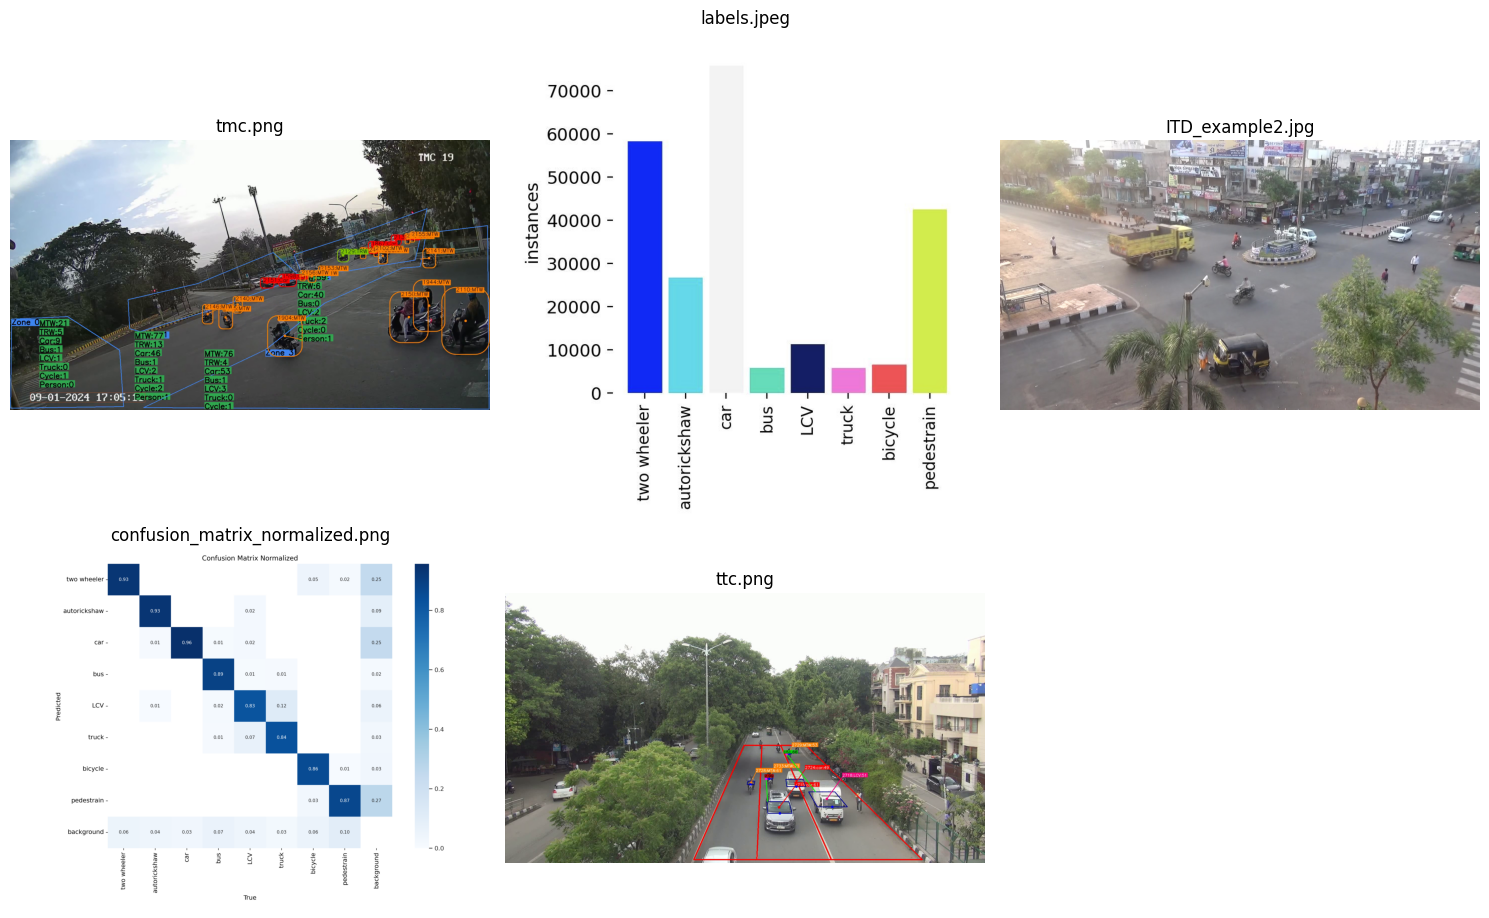

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

sample_images = image_files[:5]

plt.figure(figsize=(15, 10))

for i, path in enumerate(sample_images):
    img = Image.open(path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(path))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

annotation_extensions = (".json", ".xml", ".txt", ".csv")

annotation_files = []

for root, dirs, files in os.walk(audit_path):
    for file in files:
        if file.lower().endswith(annotation_extensions):
            annotation_files.append(os.path.join(root, file))

print("Total annotation-related files:", len(annotation_files))

for path in annotation_files:
    print(path)

Total annotation-related files: 0


In [ ]:
import os

all_files = []

for root, dirs, files in os.walk(audit_path):
    for file in files:
        all_files.append(os.path.join(root, file))

print("Total files in repository:", len(all_files))

print("\nRepository file list:")
for path in all_files:
    print(os.path.relpath(path, audit_path))

Total files in repository: 17

Repository file list:
.nojekyll
index.html
.gitignore
README.md
LICENSE
static/tmc.png
static/labels.jpeg
static/ITD_example2.jpg
static/confusion_matrix_normalized.png
static/ttc.png
static/PR_curve.png
static/ITD_example1.jpg
static/F1_curve.png
static/ITD_example3.jpg
static/lane_behaviour.png
model_weights/download_v1_1.html
model_weights/download_v1_2.html


In [ ]:
import pandas as pd
import os

audit_summary = pd.DataFrame({
    "Audit Metric": [
        "Total image files",
        "Readable images",
        "Missing images",
        "Unreadable images",
        "Annotation files",
        "Visualised sample images"
    ],
    "Result": [
        len(image_files),
        len(image_df),
        len(missing_images),
        len(unreadable_images),
        len(annotation_files),
        min(5, len(image_files))
    ]
})

display(audit_summary)

summary_path = os.path.join(audit_path, "skill5_image_audit_summary.csv")
audit_summary.to_csv(summary_path, index=False)

print("\nAudit summary saved successfully:")
print(summary_path)

,Audit Metric,Result
0,Total image files,10
1,Readable images,10
2,Missing images,0
3,Unreadable images,0
4,Annotation files,0
5,Visualised sample images,5



Audit summary saved successfully:
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/skill5_image_audit_summary.csv


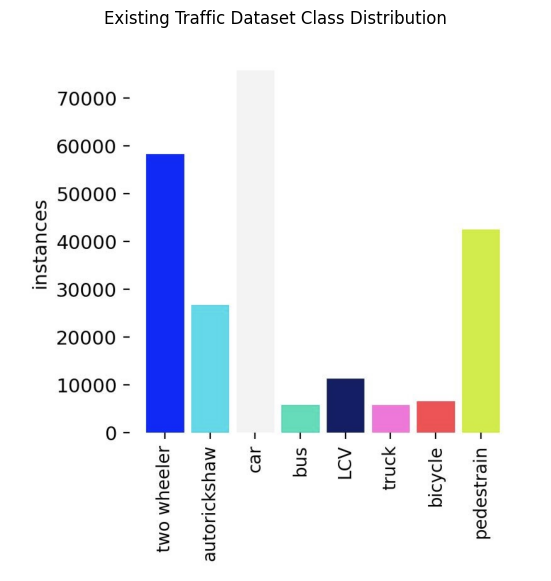

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

labels_path = os.path.join(audit_path, "static", "labels.jpeg")

img = Image.open(labels_path)

plt.figure(figsize=(12, 7))
plt.imshow(img)
plt.title("Existing Traffic Dataset Class Distribution")
plt.axis("off")
plt.show()

,Class,Approximate Instances
0,Two wheeler,58000
1,Autorickshaw,27000
2,Car,76000
3,Bus,6000
4,LCV,11000
5,Truck,6000
6,Bicycle,7000
7,Pedestrian,42000


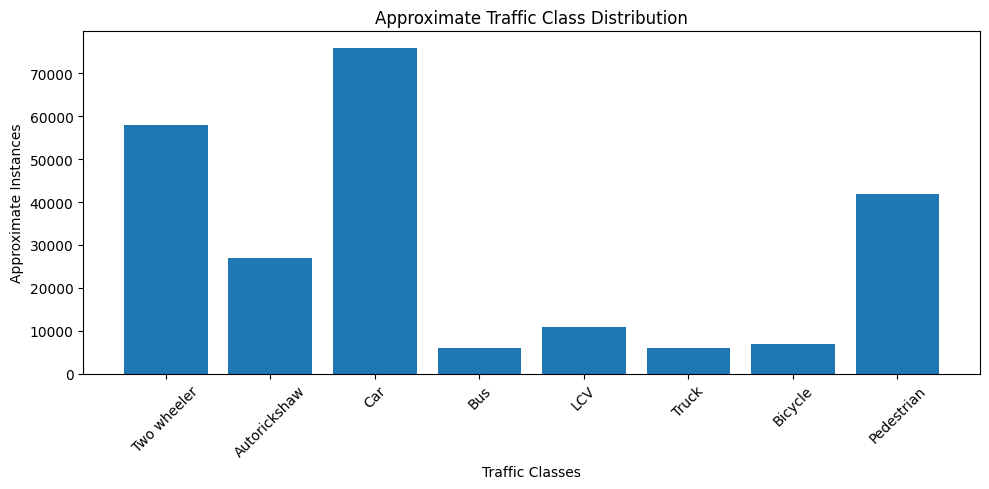

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

class_data = {
    "Class": [
        "Two wheeler",
        "Autorickshaw",
        "Car",
        "Bus",
        "LCV",
        "Truck",
        "Bicycle",
        "Pedestrian"
    ],
    "Approximate Instances": [
        58000, 27000, 76000, 6000,
        11000, 6000, 7000, 42000
    ]
}

class_df = pd.DataFrame(class_data)

display(class_df)

plt.figure(figsize=(10, 5))
plt.bar(class_df["Class"], class_df["Approximate Instances"])
plt.title("Approximate Traffic Class Distribution")
plt.xlabel("Traffic Classes")
plt.ylabel("Approximate Instances")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
imbalance_report = pd.DataFrame({
    "Metric": [
        "Highest class",
        "Highest class count",
        "Lowest class",
        "Lowest class count",
        "Approximate imbalance ratio",
        "Annotation files found",
        "Bounding-box validation"
    ],
    "Result": [
        highest_class["Class"],
        highest_class["Approximate Instances"],
        lowest_class["Class"],
        lowest_class["Approximate Instances"],
        f"{imbalance_ratio:.2f}:1",
        len(annotation_files),
        "Not possible - annotations unavailable"
    ]
})

display(imbalance_report)

imbalance_path = os.path.join(
    audit_path,
    "skill5_class_imbalance_report.csv"
)

imbalance_report.to_csv(imbalance_path, index=False)

print("\nClass imbalance report saved successfully!")
print(imbalance_path)

,Metric,Result
0,Highest class,Car
1,Highest class count,76000
2,Lowest class,Bus
3,Lowest class count,6000
4,Approximate imbalance ratio,12.67:1
5,Annotation files found,0
6,Bounding-box validation,Not possible - annotations unavailable



Class imbalance report saved successfully!
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/skill5_class_imbalance_report.csv


In [ ]:
final_report = """
SKILL 5: DATASET AUDIT AND VISUALISATION

1. IMAGE QUALITY AUDIT
Total images inspected: 10
Readable images: 10
Missing images: 0
Unreadable images: 0

2. IMAGE DIMENSIONS
Image dimensions were inspected and summarised.

3. VISUALISATION
Five sample repository images were displayed.

4. CLASS DISTRIBUTION
Eight traffic classes were identified from the existing chart:
Two wheeler, Autorickshaw, Car, Bus, LCV,
Truck, Bicycle and Pedestrian.

5. CLASS IMBALANCE
Highest class: Car (approximately 76000)
Lowest class: Bus (approximately 6000)
Approximate imbalance ratio: 12.67:1

6. ANNOTATION VALIDATION
Annotation files found: 0
Bounding-box validation: Pending
Exact annotation-based class counts: Pending

7. LIMITATION
The available repository contains sample images and
existing evaluation charts, but no original annotation files.
Therefore, annotation validation and exact class-frequency
calculation require the original annotated dataset.

CONCLUSION
Image quality checks and sample visualisations were
successfully completed. Annotation-dependent audit tasks
remain pending until the original dataset is available.
"""

report_path = os.path.join(audit_path, "SKILL5_FINAL_AUDIT_REPORT.txt")

with open(report_path, "w") as file:
    file.write(final_report)

print("Final audit report created successfully!")
print(report_path)

Final audit report created successfully!
/content/drive/MyDrive/DLAC_Dataset/ITD-Indian-traffic-dataset-main-20261123T044558Z-1-001/ITD-Indian-traffic-dataset-main/SKILL5_FINAL_AUDIT_REPORT.txt


In [ ]:
import os

report_files = [
    "skill5_image_audit_summary.csv",
    "skill5_class_imbalance_report.csv",
    "SKILL5_FINAL_AUDIT_REPORT.txt"
]

print("SKILL 5 REPORT VERIFICATION")
print("---------------------------")

for filename in report_files:
    file_path = os.path.join(audit_path, filename)

    if os.path.exists(file_path):
        print("FOUND:", filename)
    else:
        print("MISSING:", filename)

SKILL 5 REPORT VERIFICATION
---------------------------
FOUND: skill5_image_audit_summary.csv
FOUND: skill5_class_imbalance_report.csv
FOUND: SKILL5_FINAL_AUDIT_REPORT.txt
